# Fig 4 · Search follows expression: skin maps, gene lists on every section, many tile queries

**Run first:** `R7_queries` (`results/queries/`), `R8_pan_cancer` (`results/pan_cancer/`) → `R9_skin_maps`
(`results/skin_maps/`). Login node,
spindle_env (the figure font); about a minute.

* **A** Skin, seed 0, the two immune programmes present in skin (R8: Spindle-naive δ > 0; stromal / perivascular,
  also present, is not shown: its expression map disagrees). Left, the query: the covariance Q = diag(σ) R_S diag(σ)
  searched for (Fig 8's query, σ matched to skin). Middle, every cell coloured by the closeness to Q of the index
  tiles around it (percentile of exact d_B^S among the index tiles, lightly smoothed over tile centres, s.d. 1 tile
  side (Fig 8: 2), only to hide the tile edges). Right, every cell coloured by the programme's expression score (mean
  over the programme genes of the z-scored log-normalised expression), not smoothed. Both as percentiles over the
  cells drawn: the main tissue (cells with >= 8 others within 40 µm, largest connected region; about 1.5 % of the
  cells, the sparse halo and fragments, left out).
* **B** Skin, seed 0, every held-out tile as a gene-set query at every size of the accuracy benchmark (`R9_skin_maps`,
  `skin_gene_set_queries.csv`: |S| = 4, 8, 16, 32 consecutive genes in a block of the tile's home niche, the tile's
  covariance cut to S): composition difference (TV over the 10x clusters) of the query tile to Spindle's top 10
  tiles (fewer if it returns fewer; none returned: left out) and to a random 10 (mean of 200 draws), shown for
  |S| = 4 and 16 (8 and 32 are in the CSV); bars = medians;
  one-sided Wilcoxon signed-rank test per size, Spindle < random (upper bound shown).
* **C** Every section's curated tissue signatures (`R7_queries`, `results/queries/lists.csv`), each searched as a
  gene-set query with Spindle (template query): Cliff's δ of the signature tile score of the 10 tiles returned
  against the other index tiles (0 = random, 1 = all above), mean ± s.d. over seeds 0–4; one dot per signature.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib import colormaps
from matplotlib.cm import ScalarMappable
from matplotlib.colors import ListedColormap, Normalize
from matplotlib.lines import Line2D
from scipy.ndimage import binary_fill_holes, label
from scipy.spatial import cKDTree
from scipy.stats import rankdata, wilcoxon

import style as ps

FIG = "fig4_skin"
RES = ROOT / "results" / "skin_maps"
PC = ROOT / "results" / "pan_cancer"
KEY = "skin_melanoma"
KEYS = ["breast_cancer", "lung_cancer", "pancreatic_cancer", "brain_cancer", "skin_melanoma"]
PROG_LABELS = {"Cytotoxic_T": "Cytotoxic T", "Myeloid": "Myeloid", "Stromal_Perivascular": "Stromal / perivascular",
               "B_Plasma": "B / plasma"}
PROG_COLORS = {"Cytotoxic_T": "#CC3311", "Myeloid": "#009988", "Stromal_Perivascular": "#0077BB",
               "B_Plasma": "#EE7733"}  # as Fig 8
SMOOTH = 1.0  # Gaussian s.d. of the closeness map, in median tile sides
STEPS = 10  # colour steps keep the PNG within budget
W_A, W_B, W_C, H = 100.0, 37.0, 43.0, 66.0
BC_TOP, BC_BOTTOM, B_YMAX = 4.0, 14.0, 1.13  # B and C share the x axis height; C's top = B's y = 1 line
C_TOP = BC_TOP + (H - BC_TOP - BC_BOTTOM) * (1 - 1 / B_YMAX)

grad = np.load(PC / "per_dataset" / KEY / "seed0_gradient.npz", allow_pickle=True)
cells = np.load(RES / "skin_cells.npz", allow_pickle=True)
assert (grad["tiles"] == cells["tiles"]).all()
PROGRAMS = pd.read_csv(PC / "programs.csv")
SHOWN = ["Myeloid", "Cytotoxic_T"]  # the immune programmes present in skin (R8)
assert not PROGRAMS[(PROGRAMS.key == KEY) & PROGRAMS.program.isin(SHOWN)].absent.any()
LISTS = pd.read_csv(ROOT / "results" / "queries" / "lists.csv")
LISTS = LISTS[LISTS.method == "spindle_partial"]
print(sorted(set(PROGRAMS.tag) | set(LISTS.tag)), "| shown:", SHOWN)


def at(fig, x, y, w, h, **kw):
    """Axes w x h mm at (x, y) mm from the panel's top-left corner."""
    W, H_ = ps.size_mm(fig)
    return fig.add_axes([x / W, 1 - (y + h) / H_, w / W, h / H_], **kw)


def text(fig, x, y, s, size=ps.LABEL_PT, ha="left", **kw):
    W, H_ = ps.size_mm(fig)
    fig.text(x / W, 1 - y / H_, s, fontsize=size, ha=ha, va="top", **kw)

['method-v2'] | shown: ['Myeloid', 'Cytotoxic_T']


## A · The query, the closeness of every cell's tile to it and the programme's expression, cell by cell

main tissue: 86,194 of 87,499 cells drawn
figures/fig4_skin/panels/A.pdf/.png: 100 x 66 mm, 0.7 / 1.5 MB


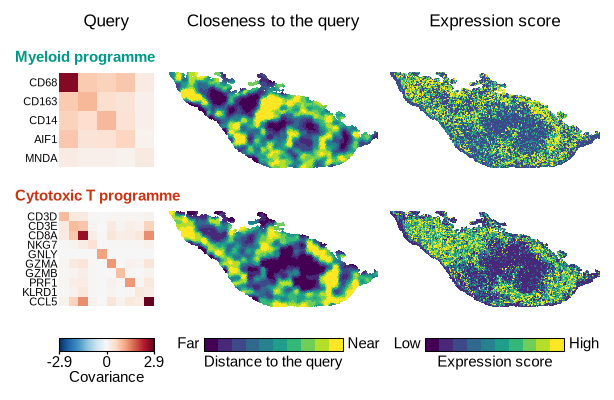

In [2]:
def main_tissue(xy, r=40.0, k=8, px=25.0):
    """Cells drawn: those with at least k other cells within r microns (drops the sparse halo and stray cells), then
    only the largest connected region of their px-micron occupancy grid (drops the small fragments off the section)."""
    dense = np.array([len(v) for v in cKDTree(xy).query_ball_point(xy, r)]) - 1 >= k
    ij = ((xy - xy.min(0)) // px).astype(int)
    occ = np.zeros(ij.max(0) + 1, bool)
    occ[ij[dense, 0], ij[dense, 1]] = True
    lab, _ = label(binary_fill_holes(occ))
    sizes = np.bincount(lab.ravel())
    sizes[0] = 0
    return dense & (lab[ij[:, 0], ij[:, 1]] == np.argmax(sizes))


KEEP = main_tissue(cells["xy"])
print(f"main tissue: {KEEP.sum():,} of {len(KEEP):,} cells drawn")
XY = cells["xy"][KEEP]
X0, Y0 = XY.min(0)
X1, Y1 = XY.max(0)
CMAP = ListedColormap(colormaps["viridis"](np.linspace(0, 1, STEPS)))
Q_MAX = max(np.abs(cells[f"Q_{p}"]).max() for p in SHOWN)


def percentile(v):
    return (rankdata(v) - 1) / (len(v) - 1)


def closeness_cells(prog):
    """Every cell coloured by the closeness of the index tiles around it: each index tile's closeness percentile
    (1 = nearest), averaged at the cell with Gaussian weights over tile centres (s.d. SMOOTH median tile sides, tile
    area as weight; light, only to hide the tile edges), then the percentile over the cells."""
    v = 1 - percentile(grad[f"d_{prog}"])
    ctr, w = grad["centre"], grad["side"] ** 2
    s2 = 2 * (SMOOTH * np.median(grad["side"])) ** 2
    out = np.empty(len(XY))
    for i in range(0, len(XY), 4096):
        k = w * np.exp(-((XY[i:i + 4096, None, :] - ctr[None]) ** 2).sum(-1) / s2)
        out[i:i + 4096] = (k @ v) / k.sum(1)
    return percentile(out)


def expression_cells(prog):
    return percentile(cells[f"score_{prog}"][KEEP].astype(np.float64))


MAT_X, MAT_W = 8.5, 16.0
MAP_W, MAP_X, ROW0, ROW_STEP = 35.5, (27.0, 64.5), 11.0, 23.5
MAP_H = MAP_W * (Y1 - Y0) / (X1 - X0)


def cell_map(ax, xy, v):
    o = np.random.default_rng(0).permutation(len(v))  # random drawing order: no value hides another
    ax.scatter(xy[o, 0], xy[o, 1], s=0.05, c=v[o], cmap=CMAP, vmin=0, vmax=1, lw=0, rasterized=True,
               antialiased=False)
    ax.set_xlim(X0, X1)
    ax.set_ylim(Y1, Y0)
    ax.set_aspect("equal")
    ax.axis("off")


def panel_a(fig):
    for x, w, head in ((MAT_X, MAT_W, "Query"), (MAP_X[0], MAP_W, "Closeness to the query"),
                       (MAP_X[1], MAP_W, "Expression score")):
        text(fig, x + w / 2, 1.2, head, ha="center")
    for i, p in enumerate(SHOWN):
        y = ROW0 + ROW_STEP * i
        text(fig, 1.0, y - 3.6, f"{PROG_LABELS[p]} programme", size=ps.TICK_PT, fontweight="bold",
             color=PROG_COLORS[p])
        Q, genes = cells[f"Q_{p}"], [str(g) for g in cells[f"genes_{p}"]]
        ax = at(fig, MAT_X, y + (MAP_H - MAT_W) / 2, MAT_W, MAT_W)
        ax.imshow(Q, cmap=ps.DIVERGING, vmin=-Q_MAX, vmax=Q_MAX, interpolation="nearest")
        ax.set_xticks([])
        ax.set_yticks(range(len(genes)))
        ax.set_yticklabels(genes, fontsize=5.2)
        ax.tick_params(length=0, pad=1)
        for sp in ax.spines.values():
            sp.set_visible(False)
        cell_map(at(fig, MAP_X[0], y, MAP_W, MAP_H), XY, closeness_cells(p))
        cell_map(at(fig, MAP_X[1], y, MAP_W, MAP_H), XY, expression_cells(p))
    y = ROW0 + ROW_STEP * len(SHOWN) - 2.0
    cax = at(fig, MAT_X, y, MAT_W, 2.2)
    cb = fig.colorbar(ScalarMappable(Normalize(-Q_MAX, Q_MAX), colormaps[ps.DIVERGING]), cax=cax,
                      orientation="horizontal", ticks=[-Q_MAX, 0, Q_MAX])
    cb.ax.set_xticklabels([f"{-Q_MAX:.1f}", "0", f"{Q_MAX:.1f}"])
    cb.outline.set_linewidth(0.5)
    cb.ax.tick_params(labelsize=ps.TICK_PT, length=1.5, pad=1)
    text(fig, MAT_X + MAT_W / 2, y + 5.6, "Covariance", size=ps.TICK_PT, ha="center")
    for x, lo, hi, title in ((MAP_X[0], "Far", "Near", "Distance to the query"),
                             (MAP_X[1], "Low", "High", "Expression score")):
        bx, bw = x + 6.0, MAP_W - 12.0
        cax = at(fig, bx, y, bw, 2.2)
        cb = fig.colorbar(ScalarMappable(Normalize(0, 1), CMAP), cax=cax, orientation="horizontal", ticks=[])
        cb.outline.set_linewidth(0.5)
        text(fig, bx - 0.8, y - 0.1, lo, size=ps.TICK_PT, ha="right")
        text(fig, bx + bw + 0.8, y - 0.1, hi, size=ps.TICK_PT)
        text(fig, x + MAP_W / 2, y + 3.0, title, size=ps.TICK_PT, ha="center")


fig = ps.panel(W_A, H)
panel_a(fig)
ps.save_panel(fig, FIG, "A")

## B · Every skin gene-set query, every size: composition difference to Spindle's top 10 and to a random 10

       n  none  short
size                 
4     93     0     16
8     93     0      2
16    93     0      0
32    93     0      0
|S| = 4: 93 queries; median TV Spindle 0.383, random 0.570; Spindle below random in 84%; one-sided Wilcoxon p = 8.82e-13
|S| = 16: 93 queries; median TV Spindle 0.359, random 0.576; Spindle below random in 88%; one-sided Wilcoxon p = 1.20e-13
figures/fig4_skin/panels/B.pdf/.png: 37 x 66 mm, 0.0 / 0.3 MB


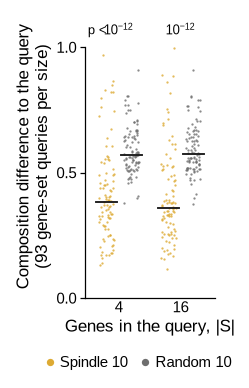

In [3]:
GQ = pd.read_csv(RES / "skin_gene_set_queries.csv")
SIZES = [4, 16]  # the smallest size and the benchmark's typical one
print(GQ.groupby("size").agg(n=("query", "size"), none=("n_found", lambda v: int((v == 0).sum())),
                             short=("n_found", lambda v: int((v < 10).sum()))))
GQ = GQ[GQ["size"].isin(SIZES) & (GQ.n_found > 0)]  # no tile returned: left out (none at seed 0)
P_TV = {}
for L, g in GQ.groupby("size"):
    P_TV[L] = wilcoxon(g.tv_spindle, g.tv_random, alternative="less").pvalue
    print(f"|S| = {L}: {len(g)} queries; median TV Spindle {g.tv_spindle.median():.3f}, random {g.tv_random.median():.3f};"
          f" Spindle below random in {(g.tv_spindle < g.tv_random).mean():.0%}; one-sided Wilcoxon p = {P_TV[L]:.2e}")


def p_bound(p):
    return f"10$^{{{int(np.ceil(np.log10(p)))}}}$"


def panel_b(fig):
    ax = ps.axes(fig, left=13.5, right=1.5, top=BC_TOP, bottom=BC_BOTTOM)
    rng = np.random.default_rng(0)
    for i, L in enumerate(SIZES):
        g = GQ[GQ["size"] == L]
        for dx, c, color in ((-0.2, "tv_spindle", ps.TIER_COLORS["spindle_partial"]), (0.2, "tv_random", ps.MUTED)):
            v = g[c].to_numpy()
            ax.scatter(i + dx + rng.uniform(-0.12, 0.12, len(v)), v, s=1.2, c=color, lw=0, alpha=0.8, zorder=2)
            ax.plot([i + dx - 0.17, i + dx + 0.17], [np.median(v)] * 2, color=ps.INK, lw=0.9, zorder=3)
        ax.text(i, 1.04, p_bound(P_TV[L]), ha="center", va="bottom", fontsize=6.0)
    ax.text(-0.5, 1.04, "p <", ha="left", va="bottom", fontsize=6.0)
    ax.set_xticks(range(len(SIZES)))
    ax.set_xticklabels([str(L) for L in SIZES])
    ax.tick_params(axis="x", length=0)
    ax.set_xlim(-0.55, len(SIZES) - 0.45)
    ax.set_ylim(0, B_YMAX)
    ax.set_yticks([0, 0.5, 1])
    ax.spines["left"].set_bounds(0, 1)
    ax.set_xlabel("Genes in the query, |S|")
    ax.set_ylabel(f"Composition difference to the query\n({GQ['query'].nunique()} gene-set queries per size)")
    handles = [Line2D([], [], ls="", marker="o", ms=2.5, color=ps.TIER_COLORS["spindle_partial"],
                      label="Spindle 10"), Line2D([], [], ls="", marker="o", ms=2.5, color=ps.MUTED,
                                                  label="Random 10")]
    fig.legend(handles=handles, ncol=2, loc="lower center", bbox_to_anchor=(0.6, 0.02), handletextpad=0.1,
               borderpad=0.2, columnspacing=0.6)


fig = ps.panel(W_B, H)
panel_b(fig)
ps.save_panel(fig, FIG, "B")

## C · Gene-list search on every section: the signature score of Spindle's 10 tiles

                     min   max  count
key                                  
brain_cancer        0.18  0.55      3
breast_cancer       0.64  0.81      5
kidney_nondiseased  0.28  0.65      2
lung_cancer         0.43  0.71      2
lymph_node          0.51  0.93      4
lymph_node_5k       0.69  0.75      2
pancreatic_cancer   0.57  0.87      3
skin_melanoma       0.79  0.88      3
figures/fig4_skin/panels/C.pdf/.png: 43 x 66 mm, 0.0 / 0.2 MB


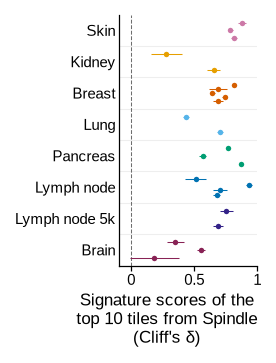

In [4]:
print(LISTS.groupby("key").delta.agg(["min", "max", "count"]).round(2))


def panel_c(fig):
    ax = ps.axes(fig, left=17.0, right=2.5, top=C_TOP, bottom=BC_BOTTOM)
    keys = ps.DATASET_ORDER
    ax.axvline(0, color=ps.MUTED, lw=0.5, ls="--", zorder=1)
    for i, k in enumerate(keys):
        t = LISTS[LISTS.key == k].sort_values("list")
        dy = np.linspace(-0.25, 0.25, len(t)) if len(t) > 1 else np.zeros(1)
        ax.errorbar(t.delta, i + dy, xerr=t.delta_sd, fmt="o", ms=2.6, color=ps.DATASET_COLORS[k], mew=0,
                    elinewidth=0.5, zorder=3)
    ax.set_ylim(len(keys) - 0.5, -0.5)
    ax.set_yticks(range(len(keys)))
    ax.set_yticklabels([ps.DATASET_LABELS[k] for k in keys])
    ax.tick_params(axis="y", length=0)
    for i in range(1, len(keys)):
        ax.axhline(i - 0.5, color="#EEEEEE", lw=0.5, zorder=0)
    ax.set_xlim(-0.1, 1.0)
    ax.set_xticks([0, 0.5, 1])
    ax.set_xticklabels(["0", "0.5", "1"])
    ax.set_xlabel("Signature scores of the\ntop 10 tiles from Spindle\n(Cliff's δ)", loc="right", multialignment="center")


fig = ps.panel(W_C, H)
panel_c(fig)
ps.save_panel(fig, FIG, "C")

## Full figure

figures/fig4_skin/fig4_skin.pdf/.png: 180 x 66 mm, 0.7 / 2.3 MB


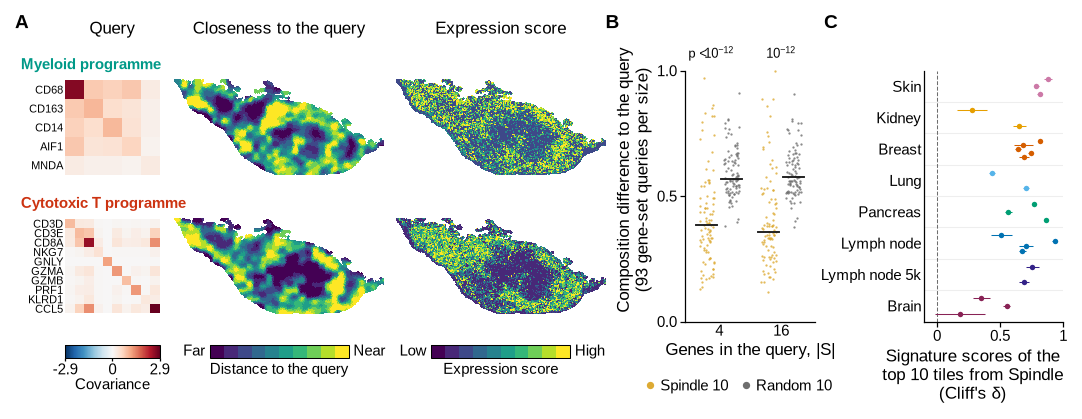

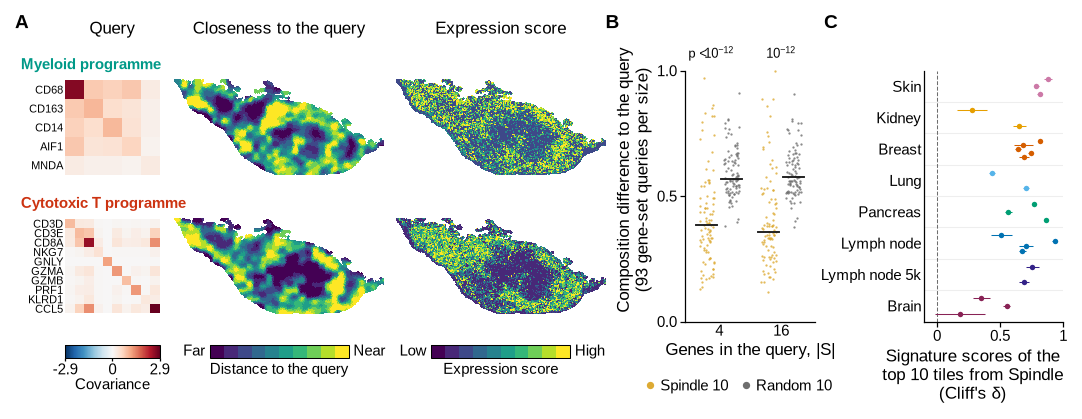

In [5]:
page = ps.page(180, H)
panel_a(ps.place(page, "A", 0, 0, W_A, H))
panel_b(ps.place(page, "B", W_A, 0, W_B, H))
panel_c(ps.place(page, "C", W_A + W_B, 0, W_C, H))
ps.save_figure(page, FIG)
page